In [5]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [6]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

In [19]:
mov_ind_array = np.arange(5)
N_training_repeats = 10
cg_params = {
    "order": 1,
}
critic_params = {
    "hidden_dim": 100,
    "embed_dim": 30,
    "layers": 2,
    "activation": "tanh",
}
opt_params = {"track_quantities": False, "quiet": True, "iterations": 50}
mi_measurement_params = {'quiet':True, 'batch_size':64, 'N_batches':500}

V_width = 1
V_E_buffer = 0
E_width = 1

train_fraction = 0.5
samp_keep = 1

In [20]:
experiment_dims = (len(mov_ind_array), N_training_repeats)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)



for mov_ind in tqdm(mov_ind_array):
    for training_repeat in range(N_training_repeats):
        cur_inds = (mov_ind, training_repeat)
        load_path = f'saved/M_latent_mov{mov_ind}.pkl'
        M = ds.load_dataset(load_path)
        V, E = M.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)

        cg_params["output_dim"] = M.N
        coarse_grainer = mds.PolynomialLayer(**cg_params)
        critic_function = mds.SeparableCritic(**critic_params)

        # make training and test subsets
        V.reset()
        E.reset()
        current_train_points, current_test_points = tools.generate_train_test_indices(
            V.P, train_fraction
        )
        V.subset_points(current_train_points)
        E.subset_points(current_train_points)
        train_points[cur_inds] = current_train_points
        test_points[cur_inds] = current_test_points

        # Train current
        als.IB(
            X=V.X,
            Y=E.X,
            coarse_grainer=coarse_grainer,
            critic_function=critic_function,
            **opt_params
        )

        # Measure InfoNCE for train
        T_train = coarse_grainer(V.X.T).numpy().T
        mi_train = als.MI_NCE(
            X=T_train, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_train[cur_inds] = mi_train["mi"]
        mi_stdevs_train[cur_inds] = mi_train["mi_stdev"]

        # Measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(current_test_points)
        E.subset_points(current_test_points)
        T_test = coarse_grainer(V.X.T).numpy().T
        mi_test = als.MI_NCE(
            X=T_test, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_test[cur_inds] = mi_test["mi"]
        mi_stdevs_test[cur_inds] = mi_test["mi_stdev"]

        coarse_grainer_array[cur_inds] = coarse_grainer
        critic_function_array[cur_inds] = critic_function
    

100%|██████████| 5/5 [00:38<00:00,  7.79s/it]


# Batch size 64

In [21]:
data = Namespace(**locals())

In [22]:
# y_test = data.mi_averages_test / np.log(2)
# yerr_test = data.mi_stdevs_test / np.log(2)
# y_train = data.mi_averages_train / np.log(2)
# yerr_train = data.mi_stdevs_train / np.log(2)
average_test = np.average(data.mi_averages_test, axis=1)
average_train = np.average(data.mi_averages_train, axis=1)
trial_variance_test = np.diag(np.cov(data.mi_averages_test))
trial_variance_train = np.diag(np.cov(data.mi_averages_train))
full_stdevs_train = np.sqrt(np.sum(data.mi_stdevs_train**2, axis=1) + trial_variance_train)
full_stdevs_test = np.sqrt(np.sum(data.mi_stdevs_test**2, axis=1) + trial_variance_test)
y_test = average_test
y_train = average_train
yerr_test = full_stdevs_test
yerr_train = full_stdevs_train
x = data.mov_ind_array

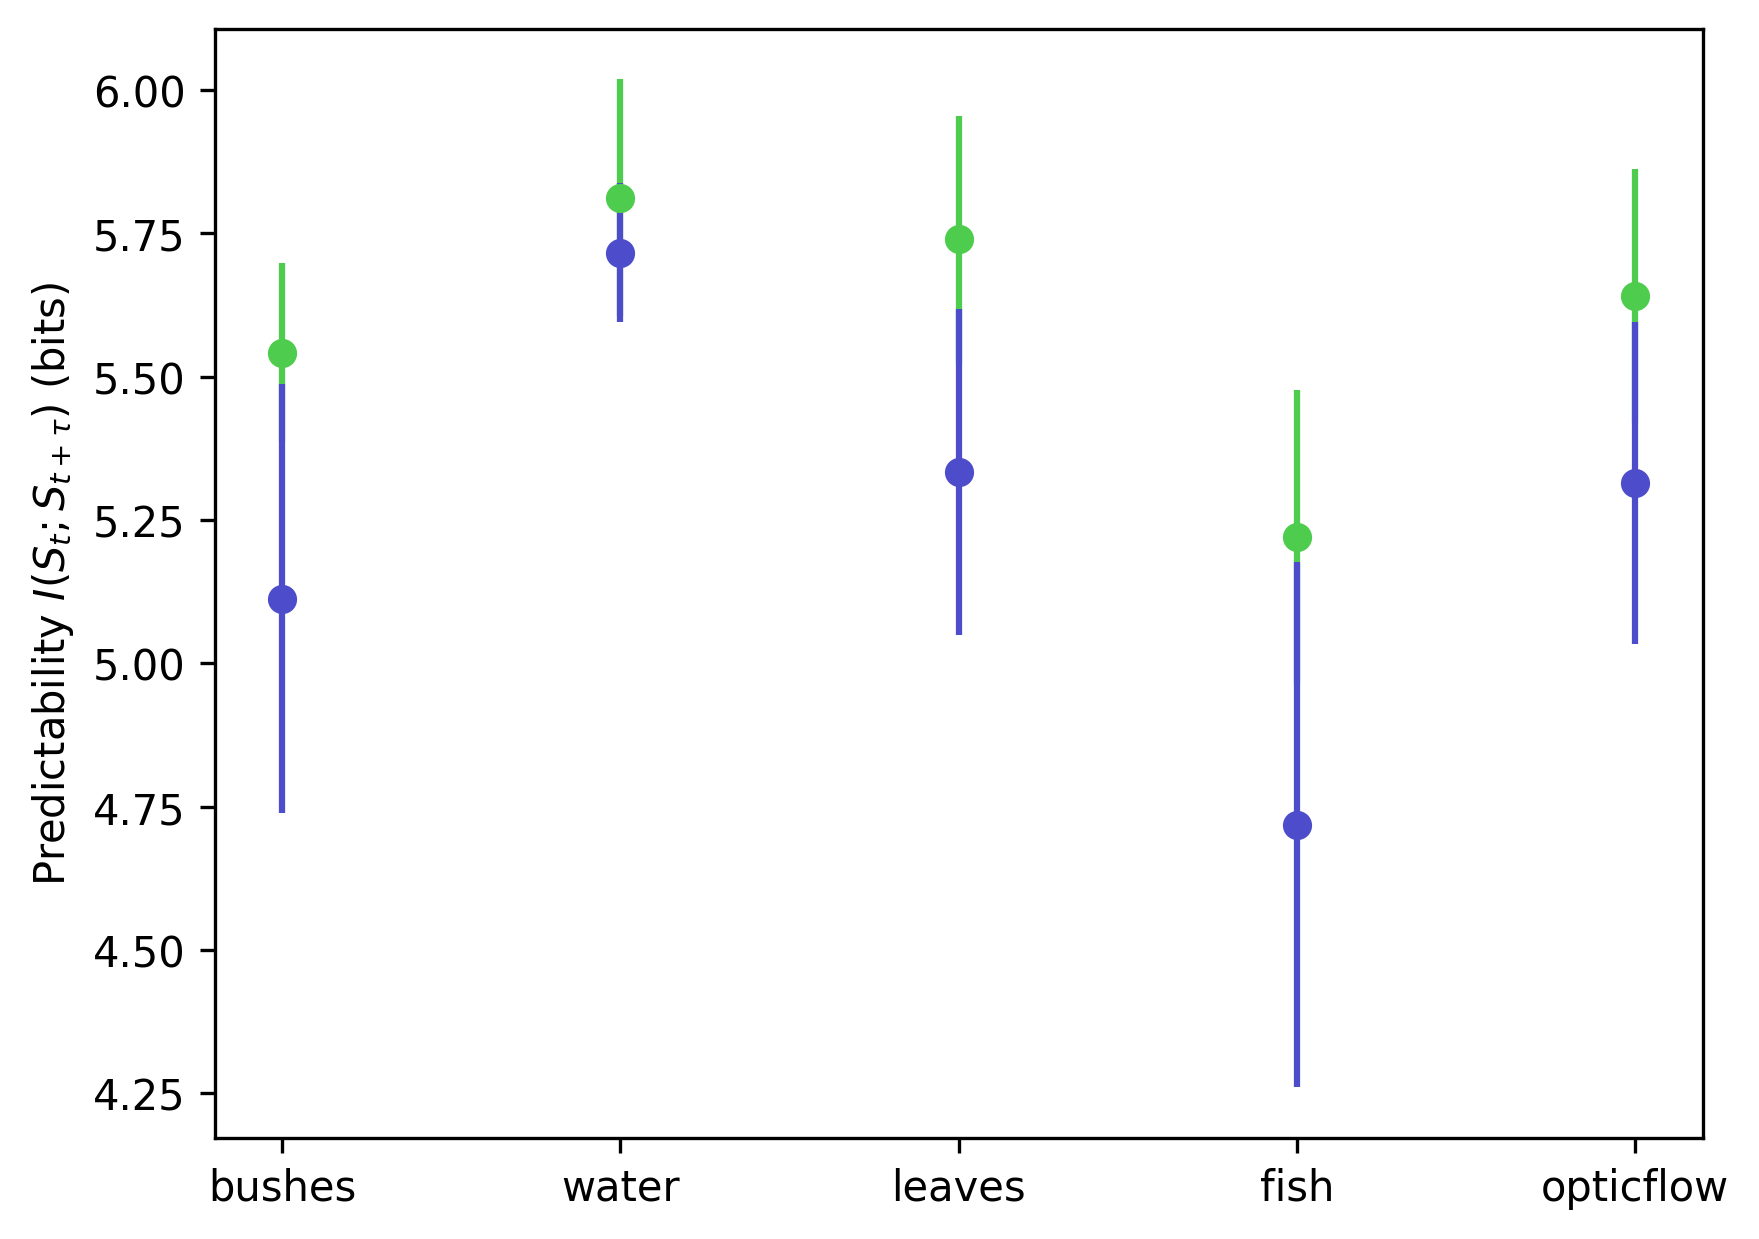

In [23]:
stimuli = ['bushes', 'water', 'leaves', 'fish', 'opticflow']
c1 = 0.3
c2 = 0.8
alp = 0.05
os = 0
fig, ax = plt.subplots(dpi=300)
ax.errorbar(x-os, y_train / np.log(2), yerr_train / np.log(2), color=(c1,c2,c1), linestyle='', marker='o')
ax.errorbar(x+os, y_test / np.log(2), yerr_test / np.log(2), color=(c1,c1,c2), linestyle='', marker='o')
ax.set_ylabel('Predictability $I(S_t; S_{t+\\tau}$) (bits)');
ax.set_xticks(x);
ax.set_xticklabels(stimuli);

In [24]:
for n, s in enumerate(stimuli):
    print(f"{s}: {y_test[n]/np.log(2):.1f} +/- {yerr_test[n]/np.log(2):.1f} bits")

bushes: 5.1 +/- 0.4 bits
water: 5.7 +/- 0.1 bits
leaves: 5.3 +/- 0.3 bits
fish: 4.7 +/- 0.5 bits
opticflow: 5.3 +/- 0.3 bits


# Batch size 1000

In [15]:
data = Namespace(**locals())

In [16]:
# y_test = data.mi_averages_test / np.log(2)
# yerr_test = data.mi_stdevs_test / np.log(2)
# y_train = data.mi_averages_train / np.log(2)
# yerr_train = data.mi_stdevs_train / np.log(2)
average_test = np.average(data.mi_averages_test, axis=1)
average_train = np.average(data.mi_averages_train, axis=1)
trial_variance_test = np.diag(np.cov(data.mi_averages_test))
trial_variance_train = np.diag(np.cov(data.mi_averages_train))
full_stdevs_train = np.sqrt(np.sum(data.mi_stdevs_train**2, axis=1) + trial_variance_train)
full_stdevs_test = np.sqrt(np.sum(data.mi_stdevs_test**2, axis=1) + trial_variance_test)
y_test = average_test
y_train = average_train
yerr_test = full_stdevs_test
yerr_train = full_stdevs_train
x = data.mov_ind_array

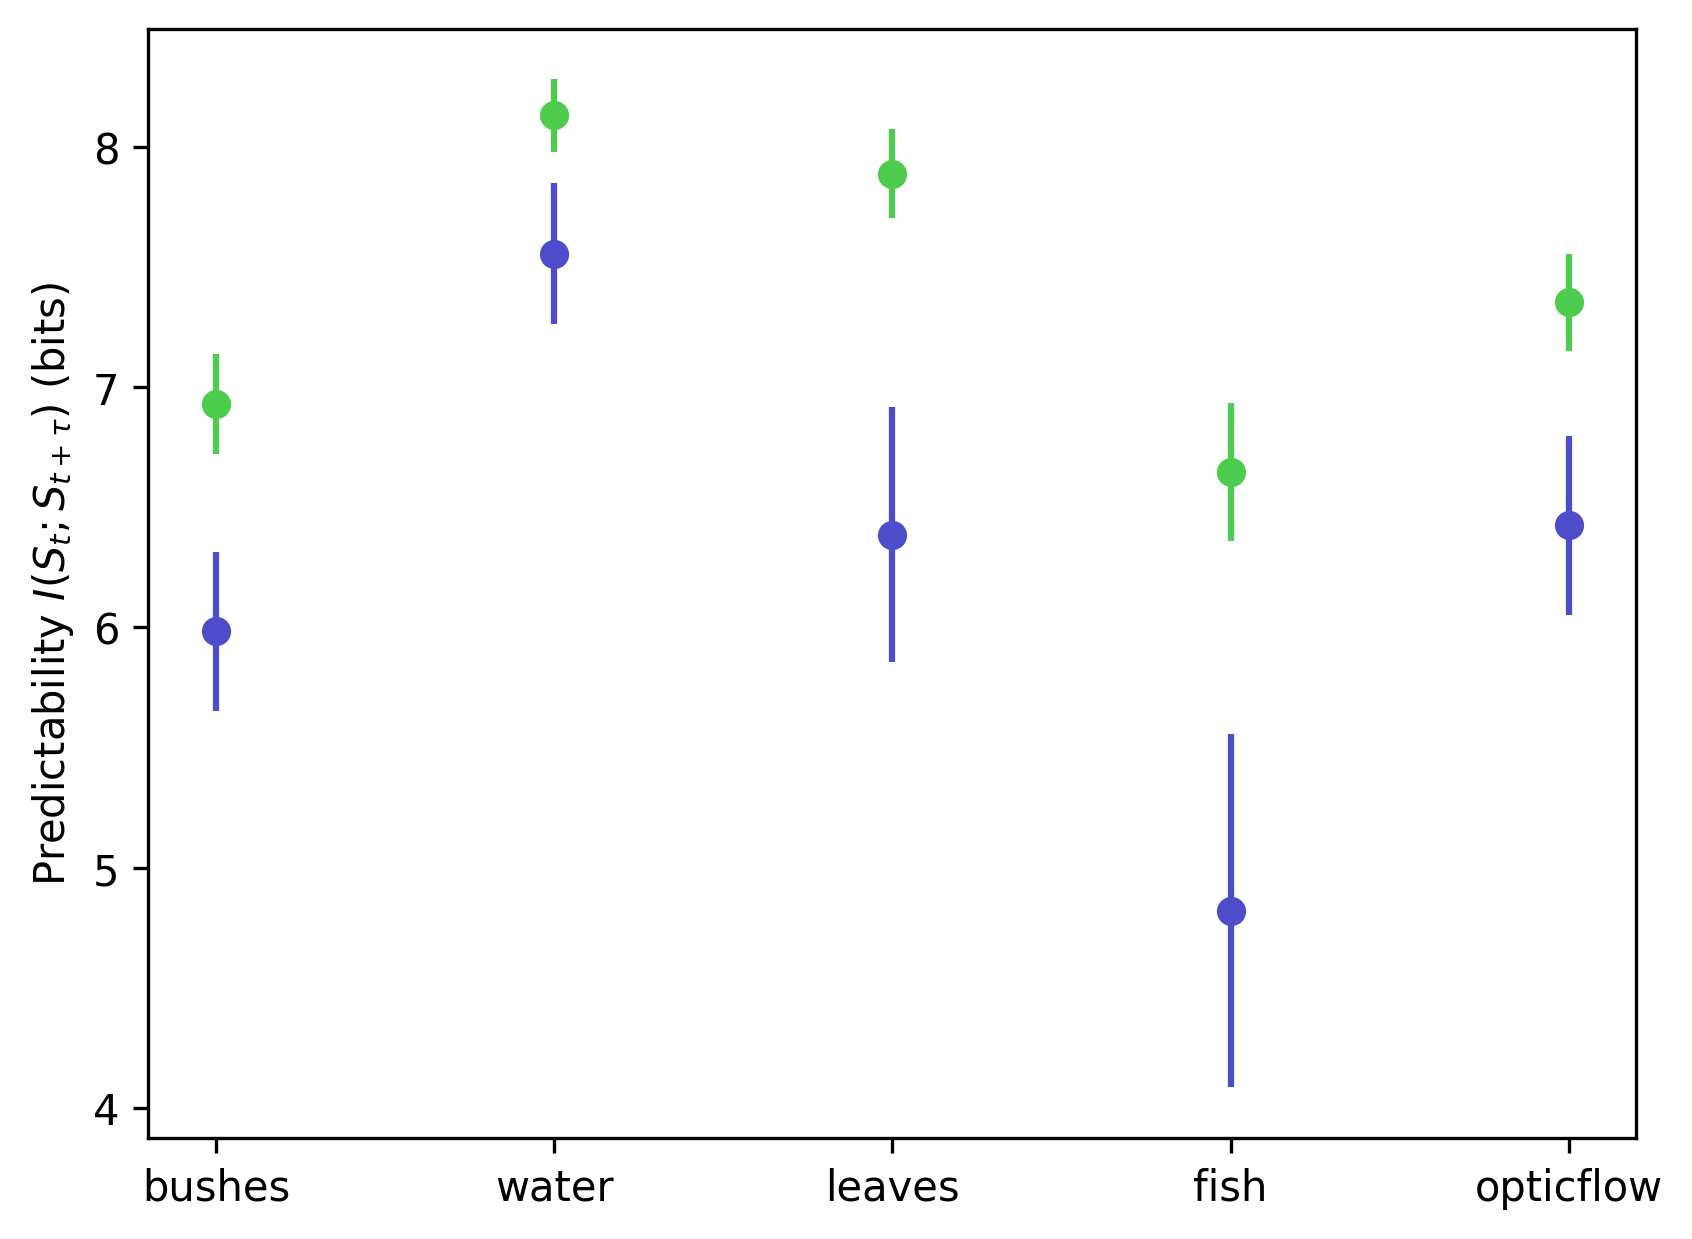

In [17]:
stimuli = ['bushes', 'water', 'leaves', 'fish', 'opticflow']
c1 = 0.3
c2 = 0.8
alp = 0.05
os = 0
fig, ax = plt.subplots(dpi=300)
ax.errorbar(x-os, y_train / np.log(2), yerr_train / np.log(2), color=(c1,c2,c1), linestyle='', marker='o')
ax.errorbar(x+os, y_test / np.log(2), yerr_test / np.log(2), color=(c1,c1,c2), linestyle='', marker='o')
ax.set_ylabel('Predictability $I(S_t; S_{t+\\tau}$) (bits)');
ax.set_xticks(x);
ax.set_xticklabels(stimuli);

In [18]:
for n, s in enumerate(stimuli):
    print(f"{s}: {y_test[n]/np.log(2):.1f} +/- {yerr_test[n]/np.log(2):.1f} bits")

bushes: 6.0 +/- 0.3 bits
water: 7.6 +/- 0.3 bits
leaves: 6.4 +/- 0.5 bits
fish: 4.8 +/- 0.7 bits
opticflow: 6.4 +/- 0.4 bits


# Batch size 250


In [9]:
data = Namespace(**locals())

In [10]:
# y_test = data.mi_averages_test / np.log(2)
# yerr_test = data.mi_stdevs_test / np.log(2)
# y_train = data.mi_averages_train / np.log(2)
# yerr_train = data.mi_stdevs_train / np.log(2)
average_test = np.average(data.mi_averages_test, axis=1)
average_train = np.average(data.mi_averages_train, axis=1)
trial_variance_test = np.diag(np.cov(data.mi_averages_test))
trial_variance_train = np.diag(np.cov(data.mi_averages_train))
full_stdevs_train = np.sqrt(np.sum(data.mi_stdevs_train**2, axis=1) + trial_variance_train)
full_stdevs_test = np.sqrt(np.sum(data.mi_stdevs_test**2, axis=1) + trial_variance_test)
y_test = average_test
y_train = average_train
yerr_test = full_stdevs_test
yerr_train = full_stdevs_train
x = data.mov_ind_array

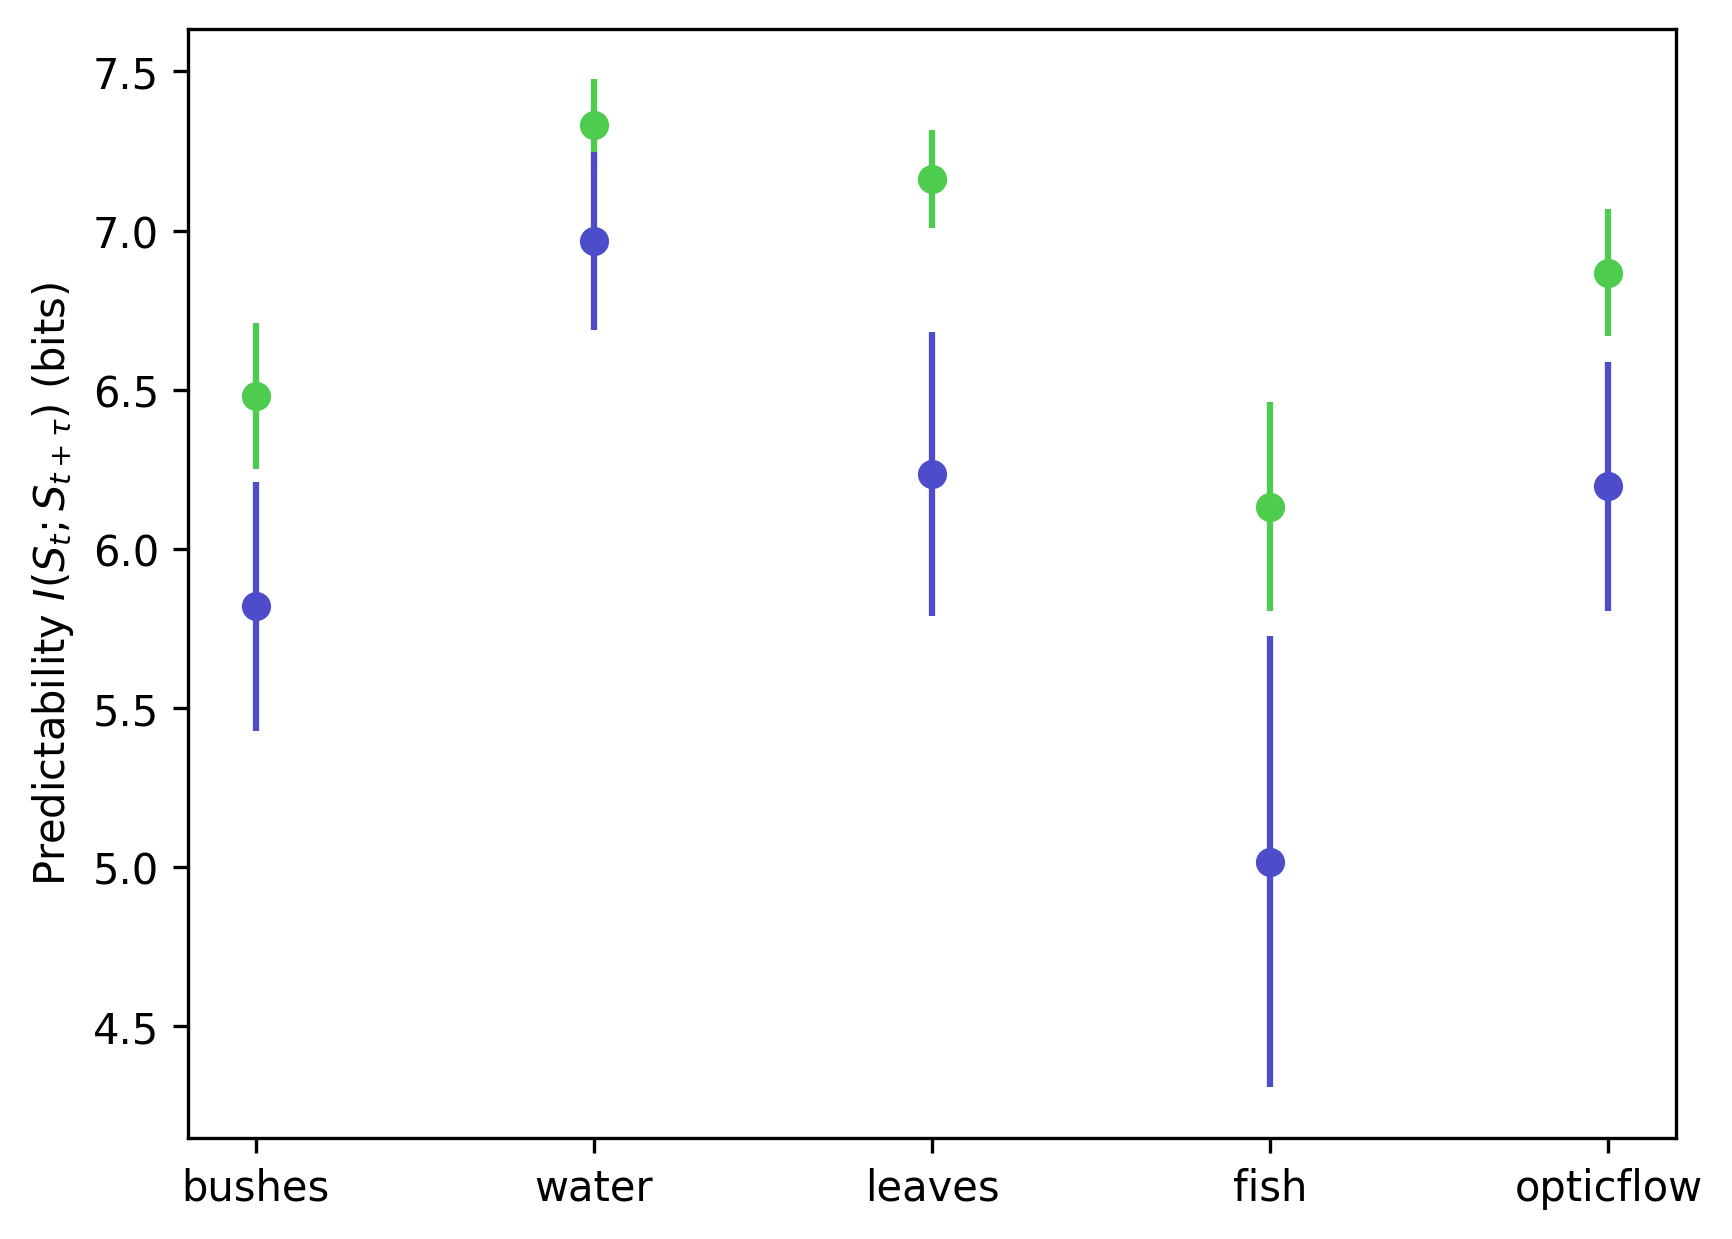

In [11]:
stimuli = ['bushes', 'water', 'leaves', 'fish', 'opticflow']
c1 = 0.3
c2 = 0.8
alp = 0.05
os = 0
fig, ax = plt.subplots(dpi=300)
ax.errorbar(x-os, y_train / np.log(2), yerr_train / np.log(2), color=(c1,c2,c1), linestyle='', marker='o')
ax.errorbar(x+os, y_test / np.log(2), yerr_test / np.log(2), color=(c1,c1,c2), linestyle='', marker='o')
ax.set_ylabel('Predictability $I(S_t; S_{t+\\tau}$) (bits)');
ax.set_xticks(x);
ax.set_xticklabels(stimuli);

In [12]:
for n, s in enumerate(stimuli):
    print(f"{s}: {y_test[n]/np.log(2):.1f} +/- {yerr_test[n]/np.log(2):.1f} bits")

bushes: 5.8 +/- 0.4 bits
water: 7.0 +/- 0.3 bits
leaves: 6.2 +/- 0.4 bits
fish: 5.0 +/- 0.7 bits
opticflow: 6.2 +/- 0.4 bits
